In [9]:
from google.colab import files
uploaded = files.upload()

Saving Untitled form.csv.zip to Untitled form.csv.zip


In [10]:
import pandas as pd

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(107, 16)


MODEL TRAINED SUCCESSFULLY!
Model: Random Forest Classifier
Training samples: 84
Testing samples: 21

Accuracy: 57.14 %

Classification Report:
                 precision    recall  f1-score   support

          Never       0.00      0.00      0.00         1
         Rarely       0.00      0.00      0.00         2
Yes, frequently       0.00      0.00      0.00         4
 Yes, sometimes       0.63      0.86      0.73        14

       accuracy                           0.57        21
      macro avg       0.16      0.21      0.18        21
   weighted avg       0.42      0.57      0.48        21


Confusion Matrix:
[[ 0  0  0  1]
 [ 0  0  0  2]
 [ 0  0  0  4]
 [ 0  2  0 12]]


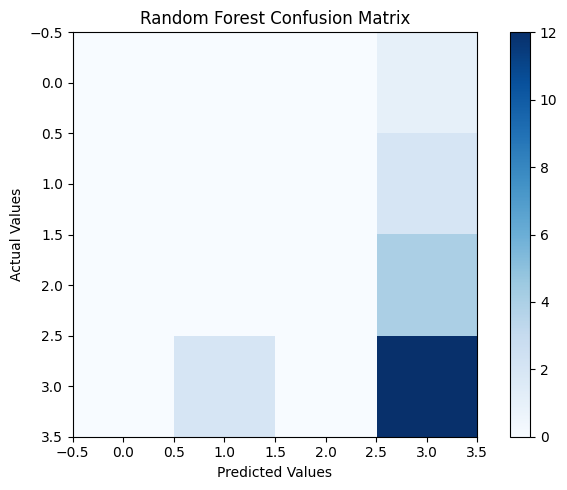

In [11]:
# MACHINE LEARNING MODEL
# Internet Usage Patterns Among Students

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

# Clean column names
df.columns = (df.columns.str.replace('\n', ' ', regex=False)
              .str.strip().str.replace(r'\s+', ' ', regex=True))

# Select input features
features = [
    "How many hours do you spend on the internet per day?",
    "What is your main purpose for using the internet?",
    "Which platform do you use most frequently?",
    "How frequently do you use the internet for academic purposes?"
]

# Select target
target = "Does internet usage sometimes distract you from your studies?"

# Prepare dataset
data = df[features + [target]].dropna(subset=[target]).copy()

X = data[features]
y = data[target].astype(str).str.strip()

# Remove categories with fewer than 2 responses
counts = y.value_counts()
valid = counts[counts >= 2].index
X = X[y.isin(valid)]
y = y[y.isin(valid)]

# Fill missing input values
for col in features:
    X[col] = X[col].fillna(X[col].mode()[0])

# Convert categorical data into numerical data
X = pd.get_dummies(X)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create and train model
model = RandomForestClassifier(
    n_estimators=50,
    random_state=42
)

model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Display results
print("MODEL TRAINED SUCCESSFULLY!")
print("Model: Random Forest Classifier")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Display confusion matrix
plt.figure(figsize=(7, 5))
plt.imshow(cm, cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.colorbar()
plt.tight_layout()
plt.show()

In [12]:
for col in features:
    print("\n", col)
    print(df[col].dropna().unique())


 How many hours do you spend on the internet per day?
['2-3hour' 'More than 3 hour' '1-2hour' 'Less than 1 hour']

 What is your main purpose for using the internet?
['Social media' 'Entertainment' 'Academic/studies' 'Other' 'Gaming'
 'News/current affairs' 'Communication']

 Which platform do you use most frequently?
['Other' 'Instagram' 'YouTube' 'Google' 'WhatsApp']

 How frequently do you use the internet for academic purposes?
['Occasionally' 'Sometimes' 'Rarely' 'Often' 'Never']


In [13]:
# PREDICTION FOR A NEW STUDENT

new_student = pd.DataFrame([{
    col: input("Enter " + col + ": ")
    for col in features
}])

# Convert input into numerical format
new_student_encoded = pd.get_dummies(new_student)

# Match training columns
new_student_encoded = new_student_encoded.reindex(
    columns=X.columns,
    fill_value=0
)

# Predict
prediction = model.predict(new_student_encoded)

print("\nPredicted Internet Usage Distraction:", prediction[0])

Enter How many hours do you spend on the internet per day?: 5 
Enter What is your main purpose for using the internet?: entertainment,academics
Enter Which platform do you use most frequently?: netflix
Enter How frequently do you use the internet for academic purposes?: often

Predicted Internet Usage Distraction: Yes, sometimes
